# PLA Ironing DoE Notebook

Ironing design, repeat prints, mass and visual-quality responses, regression, ANOVA, confirmation runs, desirability, repeatability, and interaction analysis.


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from pla_doe_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS,
    FD_I_LEVELS,
    FD_II_LEVELS,
    IRONING_FIXED_SETTINGS,
    IRONING_LEVELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_HYDROSTATIC_MEASUREMENTS,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_HYDROSTATIC_MEASUREMENTS,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_RUNS,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from DoE_old_scale import (
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    FD_I_OLD_SCALE_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    FACTOR_COLORS,
    build_mass_measurements,
    build_response_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_model_anova_table,
    build_term_significance_table,
    build_error_comparison_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_pure_error_from_replicates,
    calculate_measurement_error_from_repeated_columns,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    format_quadratic_model_formula,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_model_anova,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_screening_response_contours,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_combined_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_augmented_model_pareto,
    plot_augmented_main_effects,
    plot_augmented_observed_vs_predicted,
    plot_augmented_residuals,
    plot_screening_half_normal,
    plot_mass_measurements,
    plot_response_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
    plot_interaction_mean_matrix,
)
from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving("notebook_figures")
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


In [2]:
DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## 1) DoE Matrix


### Ironing Trial Matrix


In [62]:
# Levels and fixed settings are loaded from the compact experiment dictionaries in ffd_measurements.py.

# 4-factor half-fraction screening design plus center runs.
# Generator: D = A*B*C, so the defining relation is I = A*B*C*D.
# This gives 8 factorial runs + 3 center repeats = 11 runs total.
# Main effects are not aliased with two-factor interactions, but two-factor
# interactions are aliased in pairs: AB=CD, AC=BD, AD=BC.
ironing_base_factors = [
    "A_flow_ratio",
    "B_nozzle_temp_C",
    "C_ironing_flow_percent",
]
ironing_factorial_coded = pd.MultiIndex.from_product(
    [[-1, 1], [-1, 1], [-1, 1]],
    names=ironing_base_factors,
).to_frame(index=False)
ironing_factorial_coded["D_ironing_speed_mm_s"] = (
    ironing_factorial_coded["A_flow_ratio"]
    * ironing_factorial_coded["B_nozzle_temp_C"]
    * ironing_factorial_coded["C_ironing_flow_percent"]
)
ironing_factorial_coded = ironing_factorial_coded[list(IRONING_LEVELS)]

ironing_center_coded = pd.DataFrame([
    {factor: 0 for factor in IRONING_LEVELS}
    for _ in range(3)
])

ironing_coded = pd.concat(
    [ironing_factorial_coded, ironing_center_coded],
    ignore_index=True,
)
ironing_coded.index += 1
ironing_coded.index.name = "Run"

ironing_real = map_coded_to_real(ironing_coded, IRONING_LEVELS)
for setting, value in IRONING_FIXED_SETTINGS.items():
    ironing_real[setting] = value

print(f"Ironing design runs: {len(ironing_coded)}")
display(ironing_coded)
display(ironing_real)


Ironing design runs: 11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s
Run,,,,
1,-1,-1,-1,-1
2,-1,-1,1,1
3,-1,1,-1,1
4,-1,1,1,-1
5,1,-1,-1,1
6,1,-1,1,-1
7,1,1,-1,-1
8,1,1,1,1
9,0,0,0,0


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm
Run,,,,,,,
1,0.99,215,0,30,0.15,0.12,0.62
2,0.99,215,2,60,0.15,0.12,0.62
3,0.99,225,0,60,0.15,0.12,0.62
4,0.99,225,2,30,0.15,0.12,0.62
5,1.01,215,0,60,0.15,0.12,0.62
6,1.01,215,2,30,0.15,0.12,0.62
7,1.01,225,0,30,0.15,0.12,0.62
8,1.01,225,2,60,0.15,0.12,0.62
9,1.00,220,1,45,0.15,0.12,0.62


## 2) Measurements


### Ironing-Run Mass Measurement Placeholders


Ideal mass for ironing runs: 9.48 g


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,I1,9.452,None,9.45,NaN
1,I2,9.623,None,9.62,NaN
2,I3,9.477,None,9.48,NaN
3,I4,9.537,None,9.54,NaN
4,I5,9.551,None,9.55,NaN
5,I6,9.678,None,9.68,NaN
6,I7,9.558,None,9.56,NaN
7,I8,9.718,None,9.72,NaN
8,I9,9.500,None,9.50,NaN
9,I10,9.477,None,9.48,NaN


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
7,I8.2,9.734,None,9.73,NaN
8,I8.3,9.729,None,9.73,NaN
9,I8.4,9.690,None,9.69,NaN


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,I8.repeat mean,9.717667,NaN,9.72,0.023094


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,repeat_print_count,difference_g,abs_difference_g,difference_percent
0,I8 repeat print,I8,9.72,9.72,1,0.0,0.0,0.0


Mean absolute repeat difference: 0.000 g


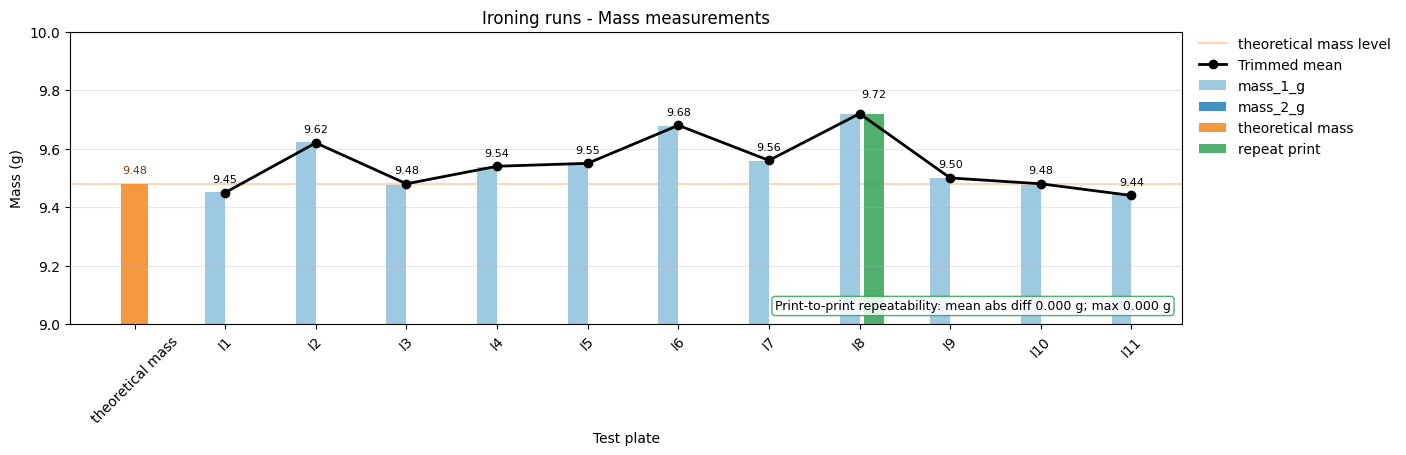

In [63]:
from ffd_utils import ideal_mass_g


ironing_mass_measurements_g, ironing_mass_columns = build_mass_measurements(
    IRONING_MASS_MEASUREMENTS_G,
    run_labels=IRONING_RUN_LABELS,
    mean_round_digits=2,
)
ironing_repeat_mass_measurements_g, ironing_repeat_mass_columns = (
    build_repeat_mass_measurements(
        IRONING_REPEAT_MASS_MEASUREMENTS_G,
        mean_round_digits=2,
    )
)
_ironing_repeat_nonempty = ironing_repeat_mass_measurements_g.dropna(
    subset=["mass_mean_g"]
).copy()
_ironing_repeat_nonempty["original_run"] = (
    _ironing_repeat_nonempty["run"].str.split(".").str[0]
)

# Average multiple repeat prints of the same original run before plotting.
ironing_repeat_mass_plot_g = (
    _ironing_repeat_nonempty
    .groupby("original_run", as_index=False)
    .agg({
        **{column: "mean" for column in ironing_repeat_mass_columns},
        "mass_mean_g": "mean",
    })
)
ironing_repeat_mass_plot_g["run"] = (
    ironing_repeat_mass_plot_g["original_run"] + ".repeat mean"
)
ironing_repeat_mass_plot_g["mass_mean_g"] = (
    ironing_repeat_mass_plot_g["mass_mean_g"].round(2)
)
ironing_repeat_mass_plot_g["mass_std_g"] = (
    _ironing_repeat_nonempty
    .groupby("original_run")["mass_mean_g"]
    .std(ddof=1)
    .reindex(ironing_repeat_mass_plot_g["original_run"])
    .to_numpy()
)
ironing_repeat_mass_plot_g = ironing_repeat_mass_plot_g[[
    "run",
    *ironing_repeat_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]]

ironing_repeatability = calculate_repeatability(
    ironing_mass_measurements_g,
    ironing_repeat_mass_plot_g,
)

volume_ironing_mm3 = 60 * 30 * 4.02
ideal_mass_ironing_g = ideal_mass_g(volume_ironing_mm3, density_g_cm3=1.31)
print(f"Ideal mass for ironing runs: {ideal_mass_ironing_g:.2f} g")

display(ironing_mass_measurements_g[[
    "run",
    *ironing_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])
display(
    ironing_repeat_mass_measurements_g.dropna(subset=["mass_mean_g"])[[
        "run",
        *ironing_repeat_mass_columns,
        "mass_mean_g",
        "mass_std_g",
    ]]
)
display(ironing_repeat_mass_plot_g)
display(ironing_repeatability)
if not ironing_repeatability.empty:
    print(
        "Mean absolute repeat difference:",
        f"{ironing_repeatability['abs_difference_g'].mean():.3f} g",
    )

plot_mass_measurements(
    ironing_mass_measurements_g,
    ironing_mass_columns,
    y_min=9,
    y_max=10,
    mean_label="Trimmed mean",
    experiment="Ironing runs",
    repeat_measurements_g=ironing_repeat_mass_plot_g,
    repeat_bar_offset=0.16,
    reference_mass_g=ideal_mass_ironing_g,
    reference_label="theoretical mass",
    value_digits=2,
)


### Ironing Confirmation-Run Mass Measurements


,run,mass_1_g,mass_mean_g,mass_std_g
0,IA,9.650,9.650,<NA>
1,IB,9.627,9.627,<NA>
2,I8-lowT,9.670,9.670,<NA>
3,I8-medT,9.656,9.656,<NA>
4,I8-T1,9.753,9.753,<NA>
5,I8-T2,9.735,9.735,<NA>
6,I8-T3,9.688,9.688,<NA>


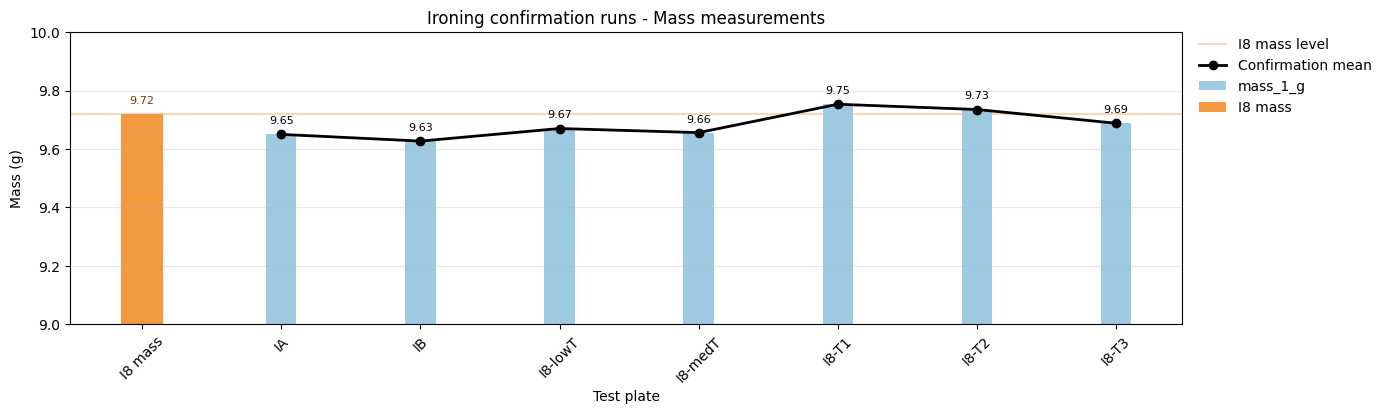

In [64]:
ironing_confirmation_mass_measurements_g = pd.DataFrame(
    IRONING_CONFIRMATION_RUNS
)[["run", "mass_mean_g"]].copy()
ironing_confirmation_mass_measurements_g["mass_1_g"] = (
    ironing_confirmation_mass_measurements_g["mass_mean_g"]
)
ironing_confirmation_mass_measurements_g["mass_std_g"] = pd.NA

i8_reference_mass_g = ironing_mass_measurements_g.loc[
    ironing_mass_measurements_g["run"] == "I8",
    "mass_mean_g",
].iloc[0]

display(ironing_confirmation_mass_measurements_g[[
    "run",
    "mass_1_g",
    "mass_mean_g",
    "mass_std_g",
]])
plot_mass_measurements(
    ironing_confirmation_mass_measurements_g,
    ["mass_1_g"],
    y_min=9,
    y_max=10,
    mean_label="Confirmation mean",
    experiment="Ironing confirmation runs",
    reference_mass_g=i8_reference_mass_g,
    reference_label="I8 mass",
    value_digits=2,
)


### Ironing Confirmation Runs


The confirmation and optimization runs are additional checks at selected settings. They are appended to an augmented ironing matrix and included in the mass-quality/desirability comparison where matching measurements are available. The original I1-I11 rows are still used alone to estimate the planned half-fraction effects, while confirmation runs remain independent checks of those estimates.


In [65]:
ironing_confirmation_runs = pd.DataFrame(IRONING_CONFIRMATION_RUNS)
display(ironing_confirmation_runs)


,run,mass_g,responses,coded_parameters,parameters,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm,visual_defects,has_stringing,quality_score,notes,mass_mean_g,extra_extrusion
0,IA,[9.65],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,2.5,,9.650,NaN
1,IB,[9.627],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.627,NaN
2,I8-lowT,[9.67],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.670,NaN
3,I8-medT,[9.656],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.656,NaN
4,I8-T1,[9.753],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.753,True
5,I8-T2,[9.735],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,15.0,,9.735,True
6,I8-T3,[9.688],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,8.0,,9.688,True


### Ironing Visual Quality Measurements


Blob count and stringing are treated as a second response. The visual quality score is calculated as `blob count + stringing penalty`; lower values are better. The default stringing penalty is 5, so one stringing observation is treated like five additional blobs. Change `STRINGING_PENALTY` if this weighting feels too strong or too weak.


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I1,7,False,0,7
1,I2,11,False,0,11
2,I3,2,False,0,2
3,I4,3,False,0,3
4,I5,6,False,0,6
5,I6,10,True,5,15
6,I7,1,False,0,1
7,I8,1,False,0,1
8,I9,2,False,0,2
9,I10,2,False,0,2


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,I8.2,2,False,0,2


,run,repeat_quality_score,original_run,original_quality_score,difference,abs_difference
0,I8.2,2,I8,1,1,1


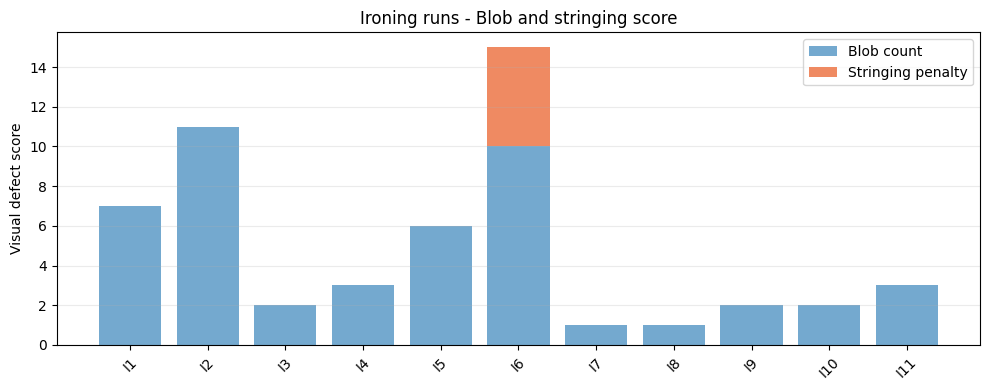

In [66]:
STRINGING_PENALTY = 5

ironing_quality_table = build_ironing_quality_table(
    IRONING_BLOB_COUNTS,
    run_labels=IRONING_RUN_LABELS,
    stringing_runs=IRONING_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)
ironing_repeat_quality_table = build_ironing_quality_table(
    IRONING_REPEAT_BLOB_COUNTS,
    stringing_runs=IRONING_REPEAT_STRINGING_RUNS,
    stringing_penalty=STRINGING_PENALTY,
)

ironing_quality_repeatability = calculate_score_repeatability(
    ironing_quality_table,
    ironing_repeat_quality_table,
    score_col="quality_score",
)

display(ironing_quality_table)
display(ironing_repeat_quality_table)
display(ironing_quality_repeatability)
plot_quality_counts(ironing_quality_table, experiment="Ironing runs")


### Ironing Confirmation-Run Visual Quality


,run,blob_count,has_stringing,stringing_penalty,quality_score
0,IA,2.5,False,0,2.5
1,IB,3.0,True,5,8.0
2,I8-T1,3.0,True,5,8.0
3,I8-T2,10.0,True,5,15.0
4,I8-T3,8.0,False,0,8.0


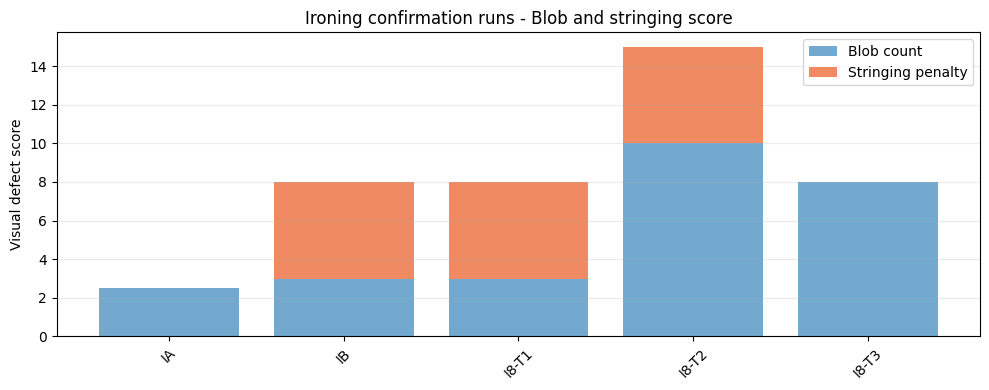

In [67]:
ironing_confirmation_quality_table = pd.DataFrame(
    IRONING_CONFIRMATION_RUNS
)[["run", "quality_score", "has_stringing"]].copy()
ironing_confirmation_quality_table = (
    ironing_confirmation_quality_table
    .dropna(subset=["quality_score"])
    .reset_index(drop=True)
)
ironing_confirmation_quality_table["stringing_penalty"] = (
    ironing_confirmation_quality_table["has_stringing"]
    .fillna(False)
    .astype(bool)
    .map({True: STRINGING_PENALTY, False: 0})
)
ironing_confirmation_quality_table["blob_count"] = (
    ironing_confirmation_quality_table["quality_score"]
    - ironing_confirmation_quality_table["stringing_penalty"]
)
ironing_confirmation_quality_table["blob_count"] = (
    ironing_confirmation_quality_table["blob_count"].clip(lower=0)
)

display(ironing_confirmation_quality_table[[
    "run",
    "blob_count",
    "has_stringing",
    "stringing_penalty",
    "quality_score",
]])
plot_quality_counts(
    ironing_confirmation_quality_table,
    experiment="Ironing confirmation runs",
)


In [68]:
ironing_design_tradeoff = build_mass_quality_tradeoff(
    ironing_mass_measurements_g,
    ironing_quality_table,
    target_mass_g=ideal_mass_ironing_g,
    mass_weight=0.5,
    quality_weight=0.5,
)

ironing_confirmation_tradeoff = ironing_confirmation_runs[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].copy()
ironing_confirmation_tradeoff["blob_count"] = pd.NA

ironing_mass_quality_tradeoff = pd.concat(
    [ironing_design_tradeoff, ironing_confirmation_tradeoff],
    ignore_index=True,
    sort=False,
)

display(ironing_mass_quality_tradeoff[[
    "run",
    "mass_mean_g",
    "quality_score",
    "has_stringing",
]].round(3))


,run,mass_mean_g,quality_score,has_stringing
0,I10,9.480,2.0,False
1,I3,9.480,2.0,False
2,I9,9.500,2.0,False
3,I11,9.440,3.0,False
4,I7,9.560,1.0,False
5,I4,9.540,3.0,False
6,I1,9.450,7.0,False
7,I5,9.550,6.0,False
8,I8,9.720,1.0,False
9,I2,9.620,11.0,False


## 3) Analysis


### Ironing Screening Analysis


This analysis uses the measured ironing runs to estimate the main effects and the aliased interaction pairs from the half-fraction design. A positive main effect means the response increases when the factor moves from its low coded level (-1) to its high coded level (+1); a negative main effect means the response decreases. The three center runs I9-I11 are still used separately for repeatability and overall curvature. A full quadratic response surface is not estimable from this 11-run, 4-factor half fraction: it would require 15 coefficients, and the individual squared terms are aliased in a two-level design. The center-point check below can detect only combined curvature, not which factor causes it.


In [69]:
ironing_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_mass_measurements_g,
    response="mass_mean_g",
)

ironing_result_matrix_with_data = ironing_result_matrix.dropna(
    subset=["mass_mean_g"]
)
print(
    f"Available ironing measurements: "
    f"{len(ironing_result_matrix_with_data)}/{len(ironing_result_matrix)}"
)
display(ironing_result_matrix_with_data)

ironing_level_coverage = build_factor_level_coverage(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)
display(
    ironing_level_coverage.pivot(
        index="factor",
        columns="coded_level",
        values="available_runs",
    ).rename(columns={-1: "low (-1)", 0: "center (0)", 1: "high (+1)"})
)


Available ironing measurements: 11/11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g
Run,,,,,
1,-1,-1,-1,-1,9.45
2,-1,-1,1,1,9.62
3,-1,1,-1,1,9.48
4,-1,1,1,-1,9.54
5,1,-1,-1,1,9.55
6,1,-1,1,-1,9.68
7,1,1,-1,-1,9.56
8,1,1,1,1,9.72
9,0,0,0,0,9.50


coded_level,low (-1),center (0),high (+1)
factor,,,
A_flow_ratio,4,3,4
B_nozzle_temp_C,4,3,4
C_ironing_flow_percent,4,3,4
D_ironing_speed_mm_s,4,3,4


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.6841,0.067


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,9.5473,9.5473,0.0202,472.7466,223489.3698,0.0000
1,A_flow_ratio,0.0525,0.1050,0.0237,2.2170,4.9149,0.0685
2,B_nozzle_temp_C,0.0000,0.0000,0.0237,0.0000,0.0000,1.0000
3,C_ironing_flow_percent,0.0650,0.1300,0.0237,2.7448,7.5339,0.0335
4,D_ironing_speed_mm_s,0.0175,0.0350,0.0237,0.7390,0.5461,0.4878


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,9.45,9.412,0.038
2,-1,-1,1,1,9.62,9.577,0.043
3,-1,1,-1,1,9.48,9.447,0.033
4,-1,1,1,-1,9.54,9.542,-0.002
5,1,-1,-1,1,9.55,9.552,-0.002
6,1,-1,1,-1,9.68,9.647,0.033
7,1,1,-1,-1,9.56,9.517,0.043
8,1,1,1,1,9.72,9.682,0.038
9,0,0,0,0,9.50,9.547,-0.047


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
4,A_flow_ratio=0|B_nozzle_temp_C=0|C_ironing_flo...,3,9.4733,0.0019,2
8,A_flow_ratio=1|B_nozzle_temp_C=1|C_ironing_flo...,4,9.7175,0.0011,3


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,2,7,0.0029,5,0.0006,0.0243


,error_basis,SS,df,MSE,s
0,regression residual,0.0269,6.0,0.0045,0.0670
1,replicate pure error,0.0029,5.0,0.0006,0.0243


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,4,0.0583,0.0146,3.2487,0.0962
1,Residual,6,0.0269,0.0045,NaN,NaN
2,Total,10,0.0852,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.0525,0.0237,2.2170,4.9149,0.0685,0.0086,6.1220,37.4788,0.0017,NaN,NaN,NaN,NaN
2,B_nozzle_temp_C,0.0000,0.0237,0.0000,0.0000,1.0000,0.0086,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN
3,C_ironing_flow_percent,0.0650,0.0237,2.7448,7.5339,0.0335,0.0086,7.5796,57.4504,0.0006,NaN,NaN,NaN,NaN
4,D_ironing_speed_mm_s,0.0175,0.0237,0.7390,0.5461,0.4878,0.0086,2.0407,4.1643,0.0968,NaN,NaN,NaN,NaN


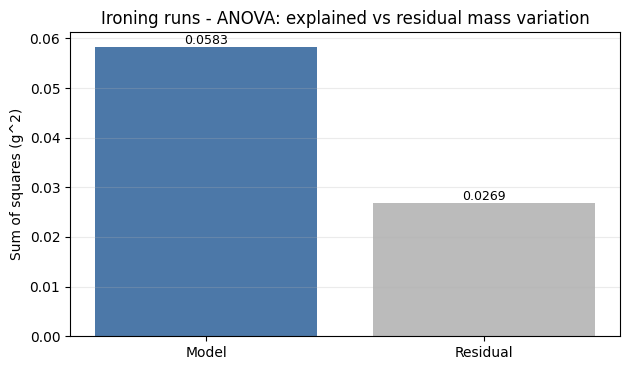

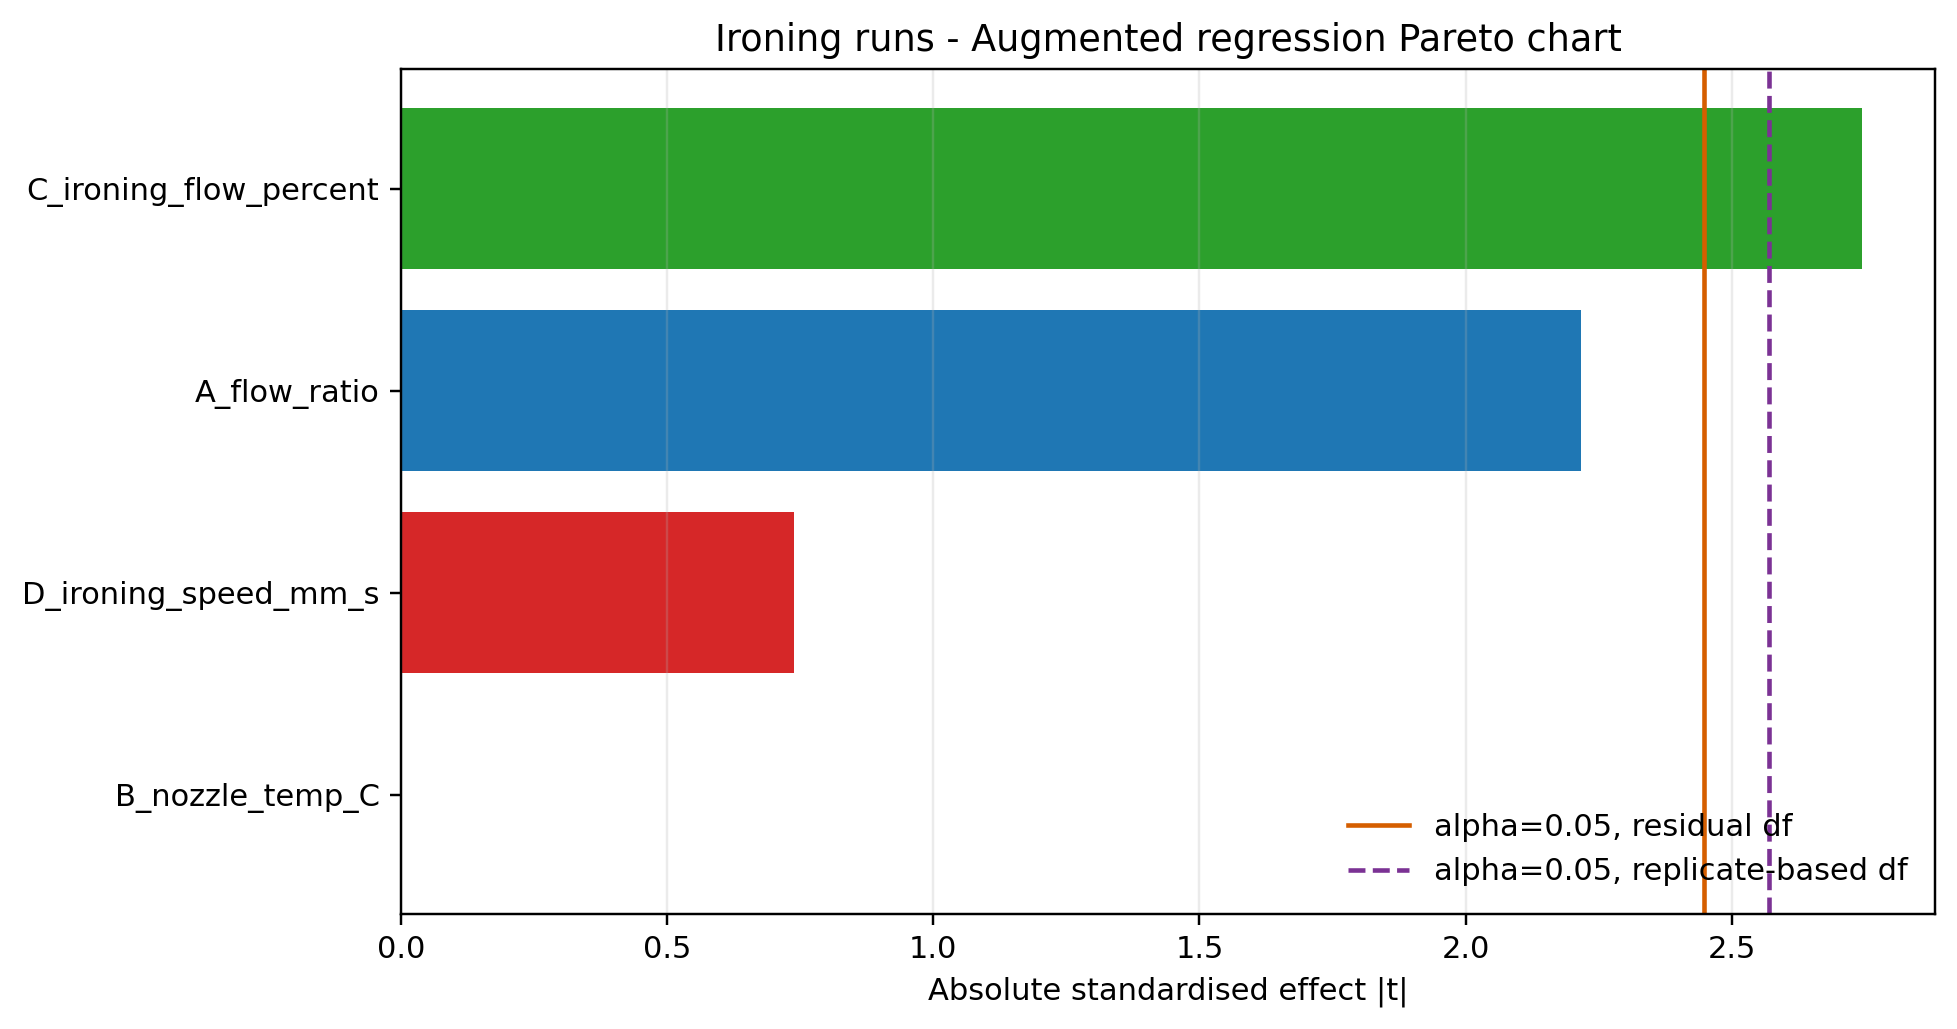

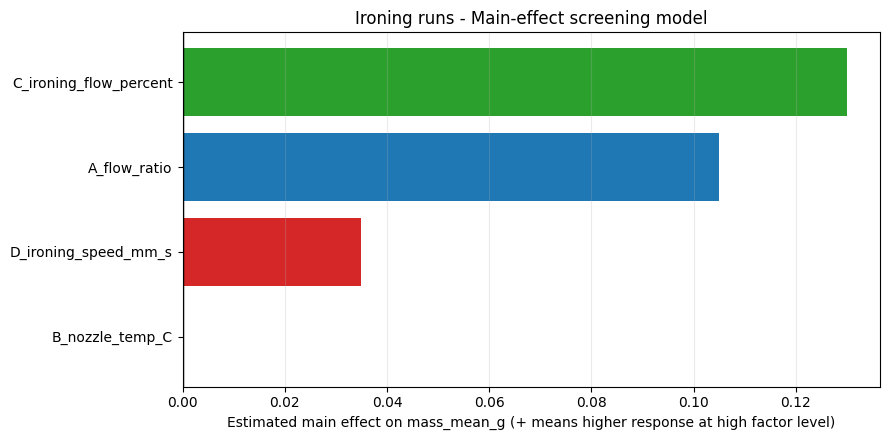

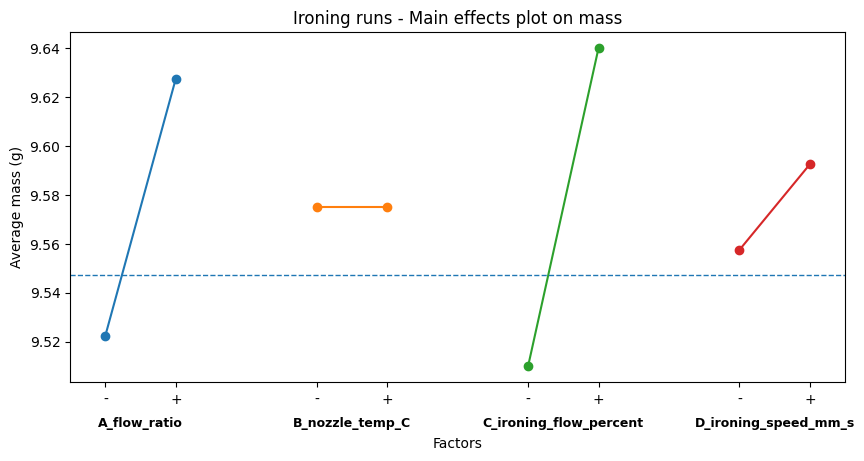

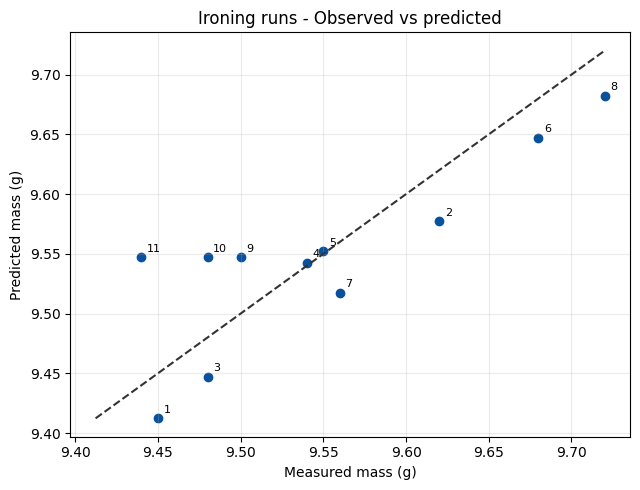

In [70]:
ironing_main_effect_model = fit_main_effect_screening_model(
    ironing_result_matrix,
    response="mass_mean_g",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_main_effect_model["info_df"].round(4))
display(ironing_main_effect_model["statistics_df"].round(4))
display(ironing_main_effect_model["fitted_df"].round(3))
ironing_mass_replicate_observations, ironing_mass_pure_error_groups, ironing_mass_pure_error_summary = (
    calculate_pure_error_from_replicates(
        ironing_result_matrix,
        response="mass_mean_g",
        factor_cols=list(IRONING_LEVELS),
        repeat_measurements_g=ironing_repeat_mass_measurements_g,
    )
)
display(ironing_mass_pure_error_groups.round(4))
display(ironing_mass_pure_error_summary.round(4))
display(build_error_comparison_table(
    ironing_main_effect_model,
    ironing_mass_pure_error_summary,
).round(4))
ironing_mass_anova_table = build_model_anova_table(ironing_main_effect_model)
display(ironing_mass_anova_table.round(4))
display(
    build_term_significance_table(
        ironing_main_effect_model,
        pure_error_summary=ironing_mass_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    ironing_mass_anova_table,
    response="mass_mean_g",
    experiment="Ironing runs",
)

if ironing_main_effect_model["info_df"].loc[0, "full_rank"]:
    plot_augmented_model_pareto(
        ironing_main_effect_model,
        experiment="Ironing runs",
        pure_error_summary=ironing_mass_pure_error_summary,
    )
    plot_screening_model_effects(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
    plot_main_effects_line(
        ironing_result_matrix_with_data,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
    plot_screening_observed_vs_predicted(
        ironing_main_effect_model,
        experiment="Ironing runs",
    )
else:
    print(
        "The available measurements do not yet provide a full-rank main-effects model. "
        "Add runs with missing factor-level combinations."
    )


#### IA and IB Confirmation-Run Comparison


The fitted ironing main-effect model predicts IA and IB from their coded settings. `prediction_error = observed mass - predicted mass`; a small absolute error supports the additive model at these mixed-level settings. IB stringing is retained as a qualitative warning and is not converted into a blob score because no blob count was supplied.


In [71]:
ironing_confirmation_comparison = build_screening_confirmation_comparison(
    ironing_main_effect_model,
    ironing_confirmation_runs,
    IRONING_LEVELS,
    response="mass_mean_g",
)

display(ironing_confirmation_comparison.round(3))
# Append confirmation runs for comparison and future augmented modeling.
ironing_design_matrix_labeled = ironing_result_matrix.copy()
ironing_design_matrix_labeled.insert(0, "run", IRONING_RUN_LABELS)
ironing_design_matrix_labeled["quality_score"] = ironing_quality_table[
    "quality_score"
].to_numpy()
ironing_design_matrix_labeled["has_stringing"] = ironing_quality_table[
    "has_stringing"
].to_numpy()
ironing_design_matrix_labeled["design_role"] = "original half-fraction / center"

ironing_confirmation_matrix = pd.DataFrame({
    "run": ironing_confirmation_comparison["run"],
    **{
        factor: ironing_confirmation_comparison[f"{factor}_coded"]
        for factor in IRONING_LEVELS
    },
    "mass_mean_g": ironing_confirmation_comparison["mass_mean_g"],
    "quality_score": ironing_confirmation_comparison["quality_score"],
    "has_stringing": ironing_confirmation_comparison["has_stringing"],
    "design_role": "additional confirmation",
})

ironing_augmented_matrix = pd.concat(
    [ironing_design_matrix_labeled, ironing_confirmation_matrix],
    ignore_index=True,
    sort=False,
)
display(ironing_augmented_matrix)


,run,mass_g,responses,coded_parameters,parameters,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm,visual_defects,has_stringing,quality_score,notes,mass_mean_g,extra_extrusion,A_flow_ratio_coded,B_nozzle_temp_C_coded,C_ironing_flow_percent_coded,D_ironing_speed_mm_s_coded,predicted_response,prediction_error,abs_prediction_error
0,IA,[9.65],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,2.5,,9.650,NaN,1.0,0.0,1.0,1.0,9.682,-0.032,0.032
1,IB,[9.627],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.627,NaN,1.0,0.0,1.0,0.0,9.665,-0.038,0.038
2,I8-lowT,[9.67],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.670,NaN,1.0,-1.0,1.0,1.0,9.682,-0.012,0.012
3,I8-medT,[9.656],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 220,...",1.01,220,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': None, 'q...",NaN,NaN,,9.656,NaN,1.0,0.0,1.0,1.0,9.682,-0.026,0.026
4,I8-T1,[9.753],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,8.0,,9.753,True,1.0,1.0,1.0,1.0,9.682,0.071,0.071
5,I8-T2,[9.735],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 215,...",1.01,215,2,60,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': True, 'q...",True,15.0,,9.735,True,1.0,-1.0,1.0,1.0,9.682,0.053,0.053
6,I8-T3,[9.688],"{'min_pressure_mbar': None, 'pump_down_speed':...",{},"{'A_flow_ratio': 1.01, 'B_nozzle_temp_C': 225,...",1.01,225,2,45,0.15,0.12,0.62,"{'blob_count': None, 'has_stringing': False, '...",False,8.0,,9.688,True,1.0,1.0,1.0,0.0,9.665,0.023,0.023


,run,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,mass_mean_g,quality_score,has_stringing,design_role
0,I1,-1.0,-1.0,-1.0,-1.0,9.450,7.0,False,original half-fraction / center
1,I2,-1.0,-1.0,1.0,1.0,9.620,11.0,False,original half-fraction / center
2,I3,-1.0,1.0,-1.0,1.0,9.480,2.0,False,original half-fraction / center
3,I4,-1.0,1.0,1.0,-1.0,9.540,3.0,False,original half-fraction / center
4,I5,1.0,-1.0,-1.0,1.0,9.550,6.0,False,original half-fraction / center
5,I6,1.0,-1.0,1.0,-1.0,9.680,15.0,True,original half-fraction / center
6,I7,1.0,1.0,-1.0,-1.0,9.560,1.0,False,original half-fraction / center
7,I8,1.0,1.0,1.0,1.0,9.720,1.0,False,original half-fraction / center
8,I9,0.0,0.0,0.0,0.0,9.500,2.0,False,original half-fraction / center
9,I10,0.0,0.0,0.0,0.0,9.480,2.0,False,original half-fraction / center


#### Ironing Visual-Quality Screening


This repeats the same screening analysis with `quality_score` as the response. For this response, positive effects are unfavorable because they mean more blobs/stringing at the high factor level; negative effects are favorable because they reduce the defect score.


The combined optimization below uses the weighted geometric mean of two desirabilities: mass is higher-is-better and visual defect score is lower-is-better. With equal weights, `D = sqrt(d_mass * d_quality)`. A zero desirability for either response makes the overall desirability zero. The current limits use the observed minimum and maximum and should later be replaced by engineering acceptance limits if available.


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score
Run,,,,,
1,-1,-1,-1,-1,7
2,-1,-1,1,1,11
3,-1,1,-1,1,2
4,-1,1,1,-1,3
5,1,-1,-1,1,6
6,1,-1,1,-1,15
7,1,1,-1,-1,1
8,1,1,1,1,1
9,0,0,0,0,2


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,11,5,5,True,6,0.7561,2.9051


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,4.8182,4.8182,0.8759,5.5008,30.2585,0.0015
1,A_flow_ratio,0.0000,0.0000,1.0271,0.0000,0.0000,1.0000
2,B_nozzle_temp_C,-4.0000,-8.0000,1.0271,-3.8945,15.1670,0.0080
3,C_ironing_flow_percent,1.7500,3.5000,1.0271,1.7038,2.9031,0.1393
4,D_ironing_speed_mm_s,-0.7500,-1.5000,1.0271,-0.7302,0.5332,0.4928


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,quality_score,predicted_response,residual
Run,,,,,,,
1,-1,-1,-1,-1,7,7.818,-0.818
2,-1,-1,1,1,11,9.818,1.182
3,-1,1,-1,1,2,-1.682,3.682
4,-1,1,1,-1,3,3.318,-0.318
5,1,-1,-1,1,6,6.318,-0.318
6,1,-1,1,-1,15,11.318,3.682
7,1,1,-1,-1,1,-0.182,1.182
8,1,1,1,1,1,1.818,-0.818
9,0,0,0,0,2,4.818,-2.818


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
4,A_flow_ratio=0|B_nozzle_temp_C=0|C_ironing_flo...,3,2.3333,0.6667,2
8,A_flow_ratio=1|B_nozzle_temp_C=1|C_ironing_flo...,2,1.5000,0.5000,1


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,2,5,1.1667,3,0.3889,0.6236


,error_basis,SS,df,MSE,s
0,regression residual,50.6364,6.0,8.4394,2.9051
1,replicate pure error,1.1667,3.0,0.3889,0.6236


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,4,157.0000,39.2500,4.6508,0.0474
1,Residual,6,50.6364,8.4394,NaN,NaN
2,Total,10,207.6364,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.00,1.0271,0.0000,0.0000,1.0000,0.2205,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN
2,B_nozzle_temp_C,-4.00,1.0271,-3.8945,15.1670,0.0080,0.2205,-18.1423,329.1429,0.0004,NaN,NaN,NaN,NaN
3,C_ironing_flow_percent,1.75,1.0271,1.7038,2.9031,0.1393,0.2205,7.9373,63.0000,0.0042,NaN,NaN,NaN,NaN
4,D_ironing_speed_mm_s,-0.75,1.0271,-0.7302,0.5332,0.4928,0.2205,-3.4017,11.5714,0.0424,NaN,NaN,NaN,NaN


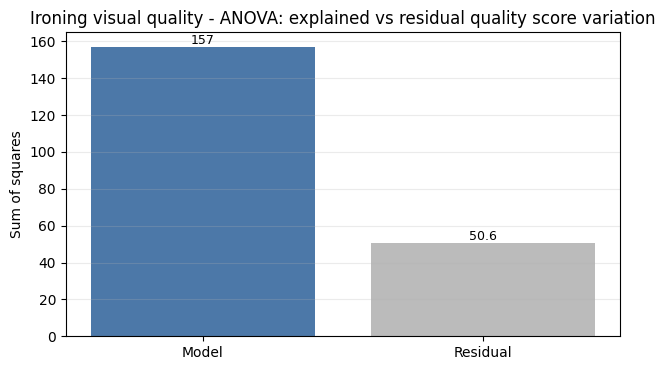

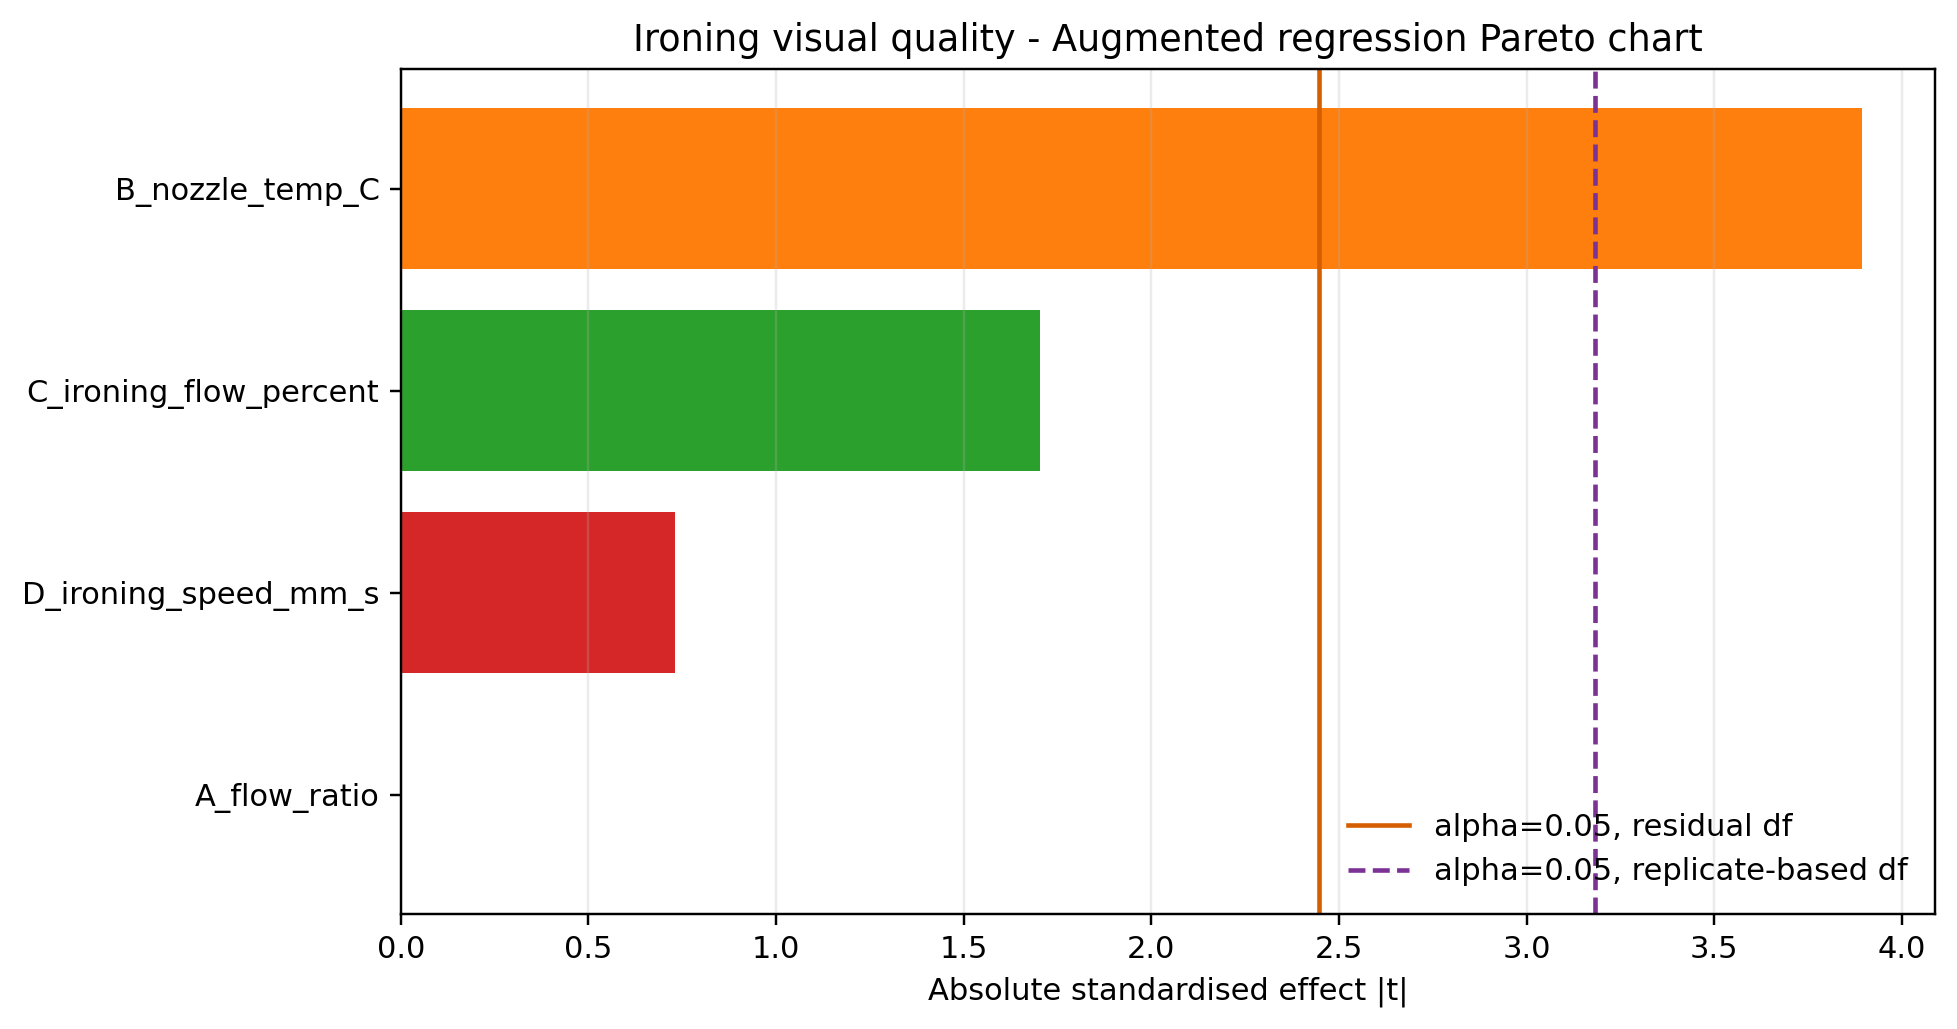

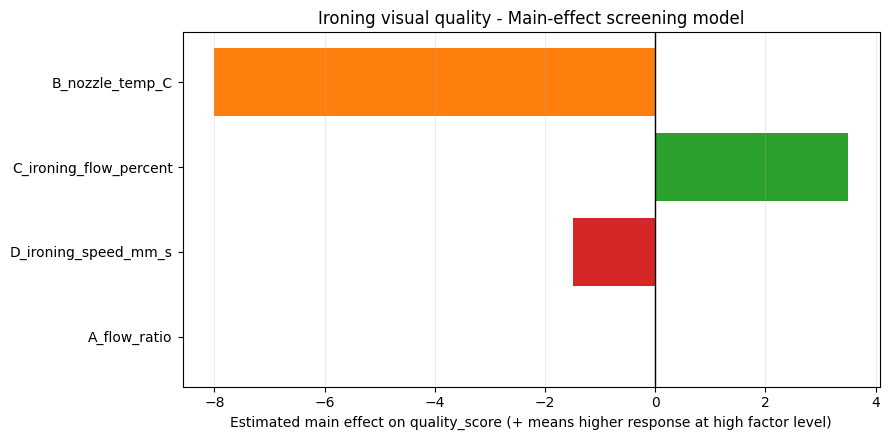

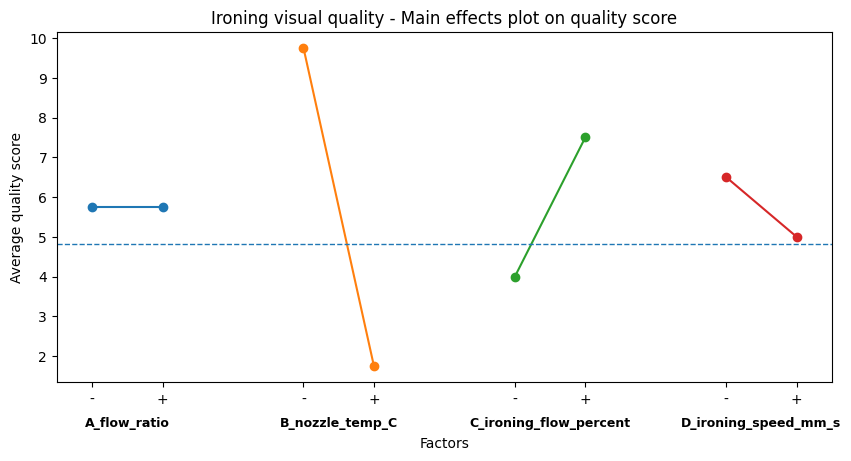

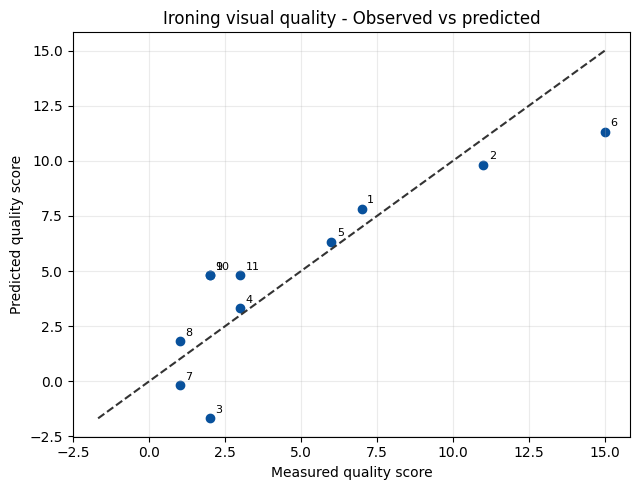

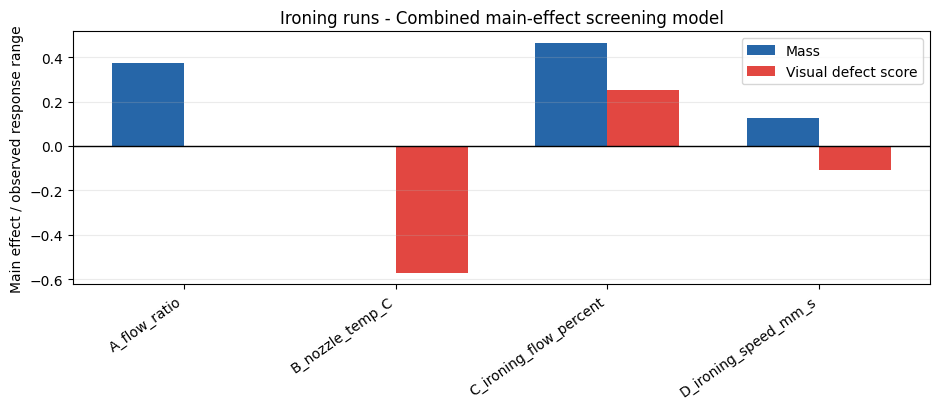

,run,mass_mean_g,quality_score,mass_desirability,quality_desirability,overall_desirability,desirability_rank
8,I8,9.720,1.0,0.895,1.000,0.946,1.0
11,IA,9.650,2.5,0.671,0.893,0.774,2.0
15,I8-T1,9.753,8.0,1.000,0.500,0.707,3.0
17,I8-T3,9.688,8.0,0.792,0.500,0.629,4.0
4,I7,9.560,1.0,0.383,1.000,0.619,5.0
12,IB,9.627,8.0,0.597,0.500,0.547,6.0
5,I4,9.540,3.0,0.319,0.857,0.523,7.0
7,I5,9.550,6.0,0.351,0.643,0.475,8.0
2,I9,9.500,2.0,0.192,0.929,0.422,9.0
9,I2,9.620,11.0,0.575,0.286,0.405,10.0


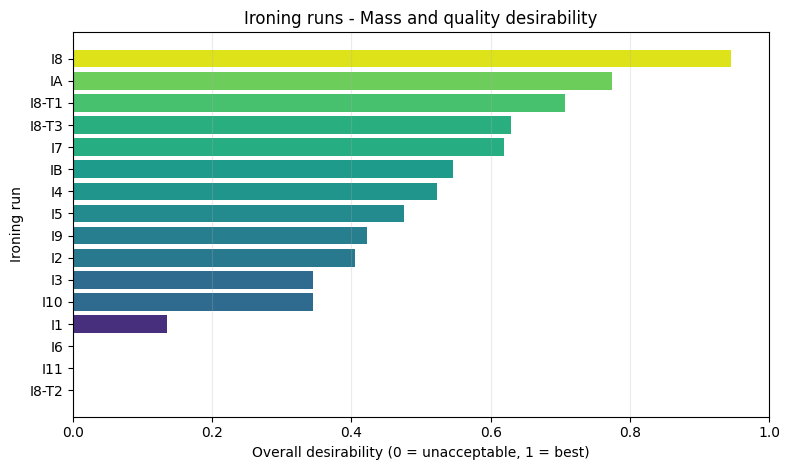

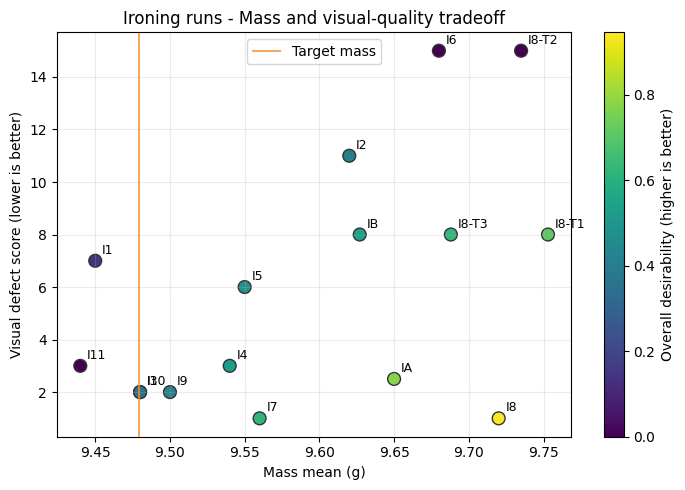

In [72]:
ironing_quality_result_matrix = build_result_matrix(
    ironing_coded,
    ironing_quality_table,
    response="quality_score",
)
ironing_quality_result_matrix_with_data = ironing_quality_result_matrix.dropna(
    subset=["quality_score"]
)

display(ironing_quality_result_matrix_with_data)

ironing_quality_model = fit_main_effect_screening_model(
    ironing_quality_result_matrix,
    response="quality_score",
    factor_cols=list(IRONING_LEVELS),
)

display(ironing_quality_model["info_df"].round(4))
display(ironing_quality_model["statistics_df"].round(4))
display(ironing_quality_model["fitted_df"].round(3))
ironing_quality_replicate_observations, ironing_quality_pure_error_groups, ironing_quality_pure_error_summary = (
    calculate_pure_error_from_replicates(
        ironing_quality_result_matrix,
        response="quality_score",
        factor_cols=list(IRONING_LEVELS),
        repeat_measurements_g=ironing_repeat_quality_table,
        repeat_response="quality_score",
    )
)
display(ironing_quality_pure_error_groups.round(4))
display(ironing_quality_pure_error_summary.round(4))
display(build_error_comparison_table(
    ironing_quality_model,
    ironing_quality_pure_error_summary,
).round(4))
ironing_quality_anova_table = build_model_anova_table(ironing_quality_model)
display(ironing_quality_anova_table.round(4))
display(
    build_term_significance_table(
        ironing_quality_model,
        pure_error_summary=ironing_quality_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    ironing_quality_anova_table,
    response="quality_score",
    experiment="Ironing visual quality",
)

if ironing_quality_model["info_df"].loc[0, "full_rank"]:
    plot_augmented_model_pareto(
        ironing_quality_model,
        experiment="Ironing visual quality",
        pure_error_summary=ironing_quality_pure_error_summary,
    )
    plot_screening_model_effects(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
    plot_main_effects_line(
        ironing_quality_result_matrix_with_data,
        response="quality_score",
        experiment="Ironing visual quality",
    )
    plot_screening_observed_vs_predicted(
        ironing_quality_model,
        experiment="Ironing visual quality",
    )
else:
    print("The visual-quality measurements do not provide a full-rank main-effects model yet.")

if (
    ironing_main_effect_model["info_df"].loc[0, "full_rank"]
    and ironing_quality_model["info_df"].loc[0, "full_rank"]
):
    plot_combined_screening_model_effects(
        {
            "mass": ironing_main_effect_model,
            "visual quality": ironing_quality_model,
        },
        response_labels={
            "mass": "Mass",
            "visual quality": "Visual defect score",
        },
        normalize=True,
        experiment="Ironing runs",
    )

# Limits are based on the observed ironing runs and can be replaced by
# engineering acceptance limits when those are defined.
MASS_DESIRABILITY_LOW = ironing_mass_quality_tradeoff["mass_mean_g"].min()
MASS_DESIRABILITY_HIGH = ironing_mass_quality_tradeoff["mass_mean_g"].max()
QUALITY_DESIRABILITY_BEST = ironing_mass_quality_tradeoff["quality_score"].min()
QUALITY_DESIRABILITY_WORST = ironing_mass_quality_tradeoff["quality_score"].max()

ironing_desirability = build_desirability_table(
    ironing_mass_quality_tradeoff,
    mass_low=MASS_DESIRABILITY_LOW,
    mass_high=MASS_DESIRABILITY_HIGH,
    quality_best=QUALITY_DESIRABILITY_BEST,
    quality_worst=QUALITY_DESIRABILITY_WORST,
    mass_weight=1.0,
    quality_weight=1.0,
)

display(ironing_desirability[[
    "run",
    "mass_mean_g",
    "quality_score",
    "mass_desirability",
    "quality_desirability",
    "overall_desirability",
    "desirability_rank",
]].round(3))

plot_desirability_ranking(
    ironing_desirability,
    experiment="Ironing runs",
)
plot_mass_quality_tradeoff(
    ironing_desirability,
    target_mass_g=ideal_mass_ironing_g,
    experiment="Ironing runs",
)


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,9.473,0.031,0.06,0.06,0.63,NaN


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,,
9,0,0,0,0,I9,9.50,NaN,0.027,0.027
10,0,0,0,0,I10,9.48,NaN,0.007,0.007
11,0,0,0,0,I11,9.44,NaN,-0.033,0.033


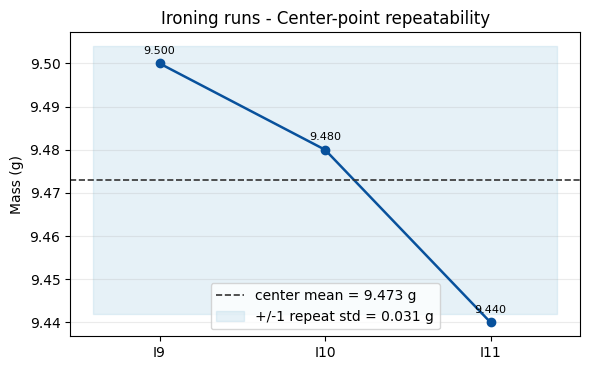

In [73]:
ironing_center_repeatability, ironing_center_repeatability_summary = (
    calculate_center_point_repeatability(
        ironing_coded,
        ironing_mass_measurements_g,
        response="mass_mean_g",
    )
)

display(ironing_center_repeatability_summary)
if not ironing_center_repeatability.empty:
    display(ironing_center_repeatability)
    plot_center_point_repeatability(
        ironing_center_repeatability,
        ironing_center_repeatability_summary,
        response="mass_mean_g",
        experiment="Ironing runs",
    )
else:
    print("Center-point repeatability will be available after measuring I9-I11.")


#### Ironing Overall Curvature Check


,factorial_runs_with_data,center_runs_with_data,factorial_mean_g,center_mean_g,overall_curvature_g,center_std_g
0,8,3,9.575,9.4733,-0.1017,0.0306


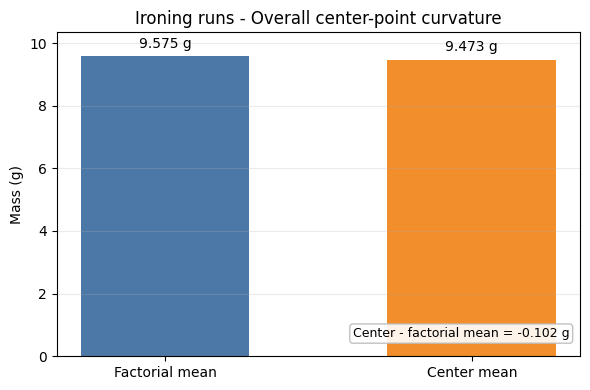

In [74]:
ironing_curvature_summary = calculate_center_curvature(
     ironing_coded,
     ironing_mass_measurements_g,
     response="mass_mean_g",
 )
display(ironing_curvature_summary.round(4))

if ironing_curvature_summary.loc[0, "center_runs_with_data"] > 0:
     plot_center_curvature(
         ironing_curvature_summary,
         experiment="Ironing runs",
     )
else:
     print(
         "Overall curvature will be available after at least one center run is measured. "
         "Measuring all I9-I11 is recommended so center repeatability can also be estimated."
     )


In [ ]:
ironing_factorial_mask = ironing_result_matrix[list(IRONING_LEVELS)].abs().eq(1).all(axis=1)
ironing_factorial_with_data = ironing_result_matrix.loc[
    ironing_factorial_mask
].dropna(subset=["mass_mean_g"])

print(
    f"Measured factorial corners: {len(ironing_factorial_with_data)}/8"
)
if len(ironing_factorial_with_data) == 8:
    ironing_interaction_effects = compute_interaction_effects(
        ironing_factorial_with_data,
        response="mass_mean_g",
    )
    display(ironing_interaction_effects)
    plot_interaction_effects(
        ironing_interaction_effects,
        experiment="Ironing runs (aliased interaction pairs)",
        response="mass_mean_g",
    )
else:
    print(
        "Interaction estimates are deferred until all 8 factorial corners are measured. "
        "The interaction pairs will remain aliased: AB=CD, AC=BD, AD=BC."
    )
